# Proyek Analisis Data: Bike Sharing Dataset (Capital Bikeshare, Washington D.C. 2011–2012)

- **Nama:** Hamizan Afza Al Isyraqi
- **Email:** hamizanafza13@gmail.com
- **ID Dicoding:** izanafza

## Menentukan Pertanyaan Bisnis

Konteks: operator layanan bike sharing ingin mengatur armada, jadwal redistribusi sepeda, dan promosi secara lebih tepat berdasarkan pola permintaan historis 2011–2012.

**Pertanyaan 1 (SMART)**
> Pada jam berapa rata-rata penyewaan per jam mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011–2012, dan berapa persen total penyewaan yang terkonsentrasi di jam sibuk (07.00–09.59 dan 16.00–19.59) pada masing-masing tipe hari, sehingga tim operasional dapat menjadwalkan redistribusi dan pemeliharaan sepeda di luar jam tersebut?

**Pertanyaan 2 (SMART)**
> Berapa persen penurunan rata-rata penyewaan harian pada cuaca berkabut dan hujan/salju ringan dibandingkan cuaca cerah pada masing-masing musim sepanjang 2011–2012, serta pengguna mana (casual atau registered) yang paling terdampak, sehingga operator dapat menyiapkan strategi armada dan insentif saat cuaca buruk?

**Pertanyaan 3 (SMART)**
> Berapa pertumbuhan total penyewaan bulanan tahun 2012 dibandingkan 2011 (year-over-year), dan pada bulan apa pertumbuhannya paling rendah, sehingga tim marketing dapat memfokuskan promosi pada bulan tersebut?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## Data Wrangling

### Gathering Data
Dataset terdiri dari dua berkas: `day.csv` (agregasi harian, 731 baris) dan `hour.csv` (agregasi per jam, 17.379 baris). Keduanya dimuat ke dalam DataFrame. Dataset per jam dipakai untuk Pertanyaan 1, dataset harian untuk Pertanyaan 2 dan 3.

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")
print("day_df :", day_df.shape)
print("hour_df:", hour_df.shape)
hour_df.head()

day_df : (731, 16)
hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight Gathering Data**
- `day.csv` berisi 731 hari (2011-01-01 s.d. 2012-12-31), `hour.csv` berisi 17.379 baris per jam.
- Kolom suhu, kelembapan, dan kecepatan angin sudah dinormalisasi sehingga perlu dikembalikan ke satuan asli agar mudah diinterpretasi.
- Kolom kategori (`season`, `weathersit`, `weekday`, `yr`) masih berupa kode angka.

### Assessing Data

In [4]:
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"===== {name} =====")
    df.info()
    print()

===== day_df =====
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

===== hour_df =====
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Dat

In [5]:
print("Missing value  :", day_df.isna().sum().sum(), "(day) |", hour_df.isna().sum().sum(), "(hour)")
print("Duplicate data :", day_df.duplicated().sum(), "(day) |", hour_df.duplicated().sum(), "(hour)")

Missing value  : 0 (day) | 0 (hour)
Duplicate data : 0 (day) | 0 (hour)


In [6]:
# Invalid value: kelembapan = 0 tidak masuk akal secara fisik
print("Hari dengan hum = 0:")
display(day_df[day_df["hum"] == 0][["dteday", "hum", "temp", "weathersit", "cnt"]])
print("Jumlah baris per jam dengan hum = 0:", (hour_df["hum"] == 0).sum())
print("Tanggal:", hour_df.loc[hour_df["hum"] == 0, "dteday"].unique())

Hari dengan hum = 0:


,dteday,hum,temp,weathersit,cnt
68,2011-03-10,0.0,0.389091,3,623


Jumlah baris per jam dengan hum = 0: 22
Tanggal: <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str


In [7]:
# Missing timestamp: seharusnya 731 hari x 24 jam = 17544 baris
expected = pd.date_range("2011-01-01", "2012-12-31 23:00", freq="h")
print("Jam yang seharusnya ada:", len(expected), "| ada di data:", len(hour_df),
      "| hilang:", len(expected) - len(hour_df))

Jam yang seharusnya ada: 17544 | ada di data: 17379 | hilang: 165


In [8]:
# Inconsistent value: definisi 'season' pada Readme vs isi data
tmp = day_df.assign(month=pd.to_datetime(day_df["dteday"]).dt.month)
print(tmp.groupby("season")["month"].agg(["min", "max"]))
print()
print(day_df.groupby("season")["cnt"].mean().round(0))

        min  max
season          
1         1   12
2         3    6
3         6    9
4         9   12

season
1    2604.0
2    4992.0
3    5644.0
4    4728.0
Name: cnt, dtype: float64


In [9]:
# Konsistensi total, jumlah kategori cuaca, dan tipe data tanggal
print("casual + registered != cnt :", ((day_df.casual + day_df.registered) != day_df.cnt).sum(),
      "(day) |", ((hour_df.casual + hour_df.registered) != hour_df.cnt).sum(), "(hour)")
print(hour_df["weathersit"].value_counts().sort_index())
print("dtype dteday:", day_df["dteday"].dtype)

casual + registered != cnt : 0 (day) | 0 (hour)
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64
dtype dteday: str


Outlier cnt (harian)       : 0
Outlier windspeed (harian) : 13
Tiga hari dengan penyewaan terendah:


,dteday,cnt,weathersit
667,2012-10-29,22,3
26,2011-01-27,431,1
725,2012-12-26,441,3


Kecepatan angin outlier tertinggi (km/jam): 34.0


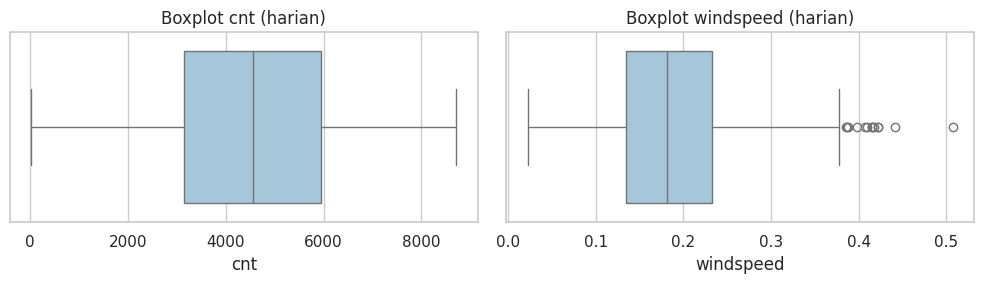

In [10]:
# Outlier (metode IQR) pada jumlah penyewaan harian & kecepatan angin
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]

print("Outlier cnt (harian)       :", len(iqr_outliers(day_df["cnt"])))
print("Outlier windspeed (harian) :", len(iqr_outliers(day_df["windspeed"])))
print("Tiga hari dengan penyewaan terendah:")
display(day_df.nsmallest(3, "cnt")[["dteday", "cnt", "weathersit"]])
print("Kecepatan angin outlier tertinggi (km/jam):", round(iqr_outliers(day_df["windspeed"]).max() * 67, 1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
sns.boxplot(x=day_df["cnt"], ax=ax[0], color="#9ecae1"); ax[0].set_title("Boxplot cnt (harian)")
sns.boxplot(x=day_df["windspeed"], ax=ax[1], color="#9ecae1"); ax[1].set_title("Boxplot windspeed (harian)")
plt.tight_layout(); plt.show()

**Insight Assessing Data**

| No | Masalah | Temuan | Tindakan di tahap Cleaning |
|----|---------|--------|----------------------------|
| 1 | *Missing value* | Tidak ada nilai kosong pada kedua dataset. | Tidak diperlukan penanganan. |
| 2 | *Duplicate data* | Tidak ada baris duplikat. | Tidak diperlukan penanganan. |
| 3 | *Invalid value* | `hum = 0` pada 2011-03-10 (1 hari di `day_df`, 22 jam di `hour_df`). Kelembapan 0% tidak realistis. | Ganti dengan median kelembapan pada bulan & tahun yang sama. |
| 4 | *Inaccurate value* (tipe data) | `dteday` bertipe string/object. | Ubah ke `datetime`. |
| 5 | *Inconsistent value* | Readme menyebut `season` 1 = springer, tetapi data menunjukkan musim 1 berisi Januari–Maret (serta akhir Desember) dengan penyewaan paling rendah, yaitu musim dingin. | Pakai label sesuai isi data: 1 = Winter, 2 = Spring, 3 = Summer, 4 = Fall. |
| 6 | *Missing timestamp* | `hour_df` hanya punya 17.379 dari 17.544 jam yang seharusnya, jadi 165 jam tidak tercatat. | Tidak diimputasi karena angka penyewaan tidak boleh dikarang. Pada agregasi rata-rata per jam, jam yang tidak tercatat otomatis tidak dihitung. |
| 7 | *Outlier* | `cnt` harian tidak memiliki outlier menurut IQR, tetapi nilai terendahnya sangat ekstrem (22 penyewaan pada 2012-10-29, saat Badai Sandy). `windspeed` harian memiliki 13 outlier (angin kencang, maks ≈34 km/jam). | Dipertahankan karena merupakan kejadian cuaca nyata, bukan kesalahan input. |
| 8 | Skala data | `temp`, `atemp`, `hum`, `windspeed` ternormalisasi. Kode kategori belum berlabel. | Kembalikan ke satuan asli dan beri label deskriptif. |

### Cleaning Data

In [11]:
# 1) Tipe data tanggal
for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])

# 2) Invalid value: hum = 0 -> median hum (bulan & tahun yang sama, tanpa nilai 0)
def fix_humidity(df):
    valid = df[df["hum"] > 0].groupby(["yr", "mnth"])["hum"].median()
    mask = df["hum"] == 0
    df.loc[mask, "hum"] = [valid[(y, m)] for y, m in zip(df.loc[mask, "yr"], df.loc[mask, "mnth"])]
    return df

day_df = fix_humidity(day_df)
hour_df = fix_humidity(hour_df)
print("hum = 0 tersisa:", (day_df.hum == 0).sum(), "(day) |", (hour_df.hum == 0).sum(), "(hour)")

hum = 0 tersisa: 0 (day) | 0 (hour)


In [12]:
# 3) Kembalikan skala asli & beri label kategori
season_map = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
weather_map = {1: "Cerah", 2: "Berkabut/Berawan", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
month_names = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

for df in (day_df, hour_df):
    df["season_label"] = df["season"].map(season_map)
    df["weather_label"] = df["weathersit"].map(weather_map)
    df["weekday_label"] = df["weekday"].map(weekday_map)
    df["year"] = df["yr"].map({0: 2011, 1: 2012})
    df["month_label"] = df["mnth"].map(lambda m: month_names[m - 1])
    df["temp_c"] = df["temp"] * 41          # suhu (°C)
    df["atemp_c"] = df["atemp"] * 50        # suhu terasa (°C)
    df["hum_pct"] = df["hum"] * 100         # kelembapan (%)
    df["wind_kmh"] = df["windspeed"] * 67   # kecepatan angin
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")

day_df[["dteday", "season_label", "weather_label", "temp_c", "hum_pct", "wind_kmh", "cnt"]].head()

,dteday,season_label,weather_label,temp_c,hum_pct,wind_kmh,cnt
0,2011-01-01,Winter,Berkabut/Berawan,14.110847,80.5833,10.749882,985
1,2011-01-02,Winter,Berkabut/Berawan,14.902598,69.6087,16.652113,801
2,2011-01-03,Winter,Cerah,8.050924,43.7273,16.636703,1349
3,2011-01-04,Winter,Cerah,8.200000,59.0435,10.739832,1562
4,2011-01-05,Winter,Cerah,9.305237,43.6957,12.522300,1600


**Insight Cleaning Data**
- Tipe `dteday` sudah `datetime`, nilai `hum = 0` sudah diganti median bulanan, dan seluruh kolom kategori punya label deskriptif.
- Outlier kecepatan angin dan 165 jam yang hilang sengaja tidak dimodifikasi agar hasil analisis tetap jujur terhadap data aslinya.

## Exploratory Data Analysis (EDA)

### Ringkasan statistik

In [13]:
day_df[["cnt", "casual", "registered", "temp_c", "hum_pct", "wind_kmh"]].describe().round(1)

,cnt,casual,registered,temp_c,hum_pct,wind_kmh
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,4504.3,848.2,3656.2,20.3,62.9,12.8
std,1937.2,686.6,1560.3,7.5,14.1,5.2
min,22.0,2.0,20.0,2.4,18.8,1.5
25%,3152.0,315.5,2497.0,13.8,52.1,9.0
50%,4548.0,713.0,3662.0,20.4,62.7,12.1
75%,5956.0,1096.0,4776.5,26.9,73.0,15.6
max,8714.0,3410.0,6946.0,35.3,97.2,34.0


In [14]:
print("Total penyewaan 2011:", day_df.loc[day_df.year == 2011, "cnt"].sum())
print("Total penyewaan 2012:", day_df.loc[day_df.year == 2012, "cnt"].sum())
print("Porsi registered    :", round(day_df["registered"].sum() / day_df["cnt"].sum() * 100, 1), "%")

Total penyewaan 2011: 1243103
Total penyewaan 2012: 2049576
Porsi registered    : 81.2 %


### Pertanyaan 1: Pada jam berapa rata-rata penyewaan per jam mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011–2012, dan berapa persen total penyewaan yang terkonsentrasi di jam sibuk (07.00–09.59 dan 16.00–19.59) pada masing-masing tipe hari, sehingga tim operasional dapat menjadwalkan redistribusi dan pemeliharaan sepeda di luar jam tersebut?

In [15]:
hourly_pattern = (hour_df.groupby(["day_type", "hr"])["cnt"].mean()
                  .unstack(0).round(1))
hourly_pattern.T

hr,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,,,,
Akhir Pekan/Libur,90.8,69.5,53.2,25.8,8.3,8.7,18.7,43.4,105.7,171.6,255.9,315.3,366.3,372.7,364.6,358.8,352.7,323.5,281.1,231.7,174.7,142.1,116.1,85.9
Hari Kerja,36.8,16.6,8.7,4.9,5.4,24.9,102.5,290.6,477.0,241.5,135.4,158.2,200.8,198.4,183.6,201.3,293.1,525.3,492.2,348.4,249.7,186.3,138.4,88.7


In [16]:
for t, g in hour_df.groupby("day_type"):
    s = g.groupby("hr")["cnt"].mean()
    print(f"{t}: 3 jam tertinggi -> {s.nlargest(3).round(0).astype(int).to_dict()} | jam terendah -> {s.idxmin()}:00")

peak_hours = [7, 8, 9, 16, 17, 18, 19]

def peak_share(df):
    s = df.groupby("hr")["cnt"].mean()
    return s.loc[peak_hours].sum() / s.sum() * 100

for t, g in hour_df.groupby("day_type"):
    print(f"Porsi 7 jam sibuk (07-09 & 16-19) terhadap total penyewaan {t}: {peak_share(g):.1f}%")

Akhir Pekan/Libur: 3 jam tertinggi -> {13: 373, 12: 366, 14: 365} | jam terendah -> 4:00
Hari Kerja: 3 jam tertinggi -> {17: 525, 18: 492, 8: 477} | jam terendah -> 3:00
Porsi 7 jam sibuk (07-09 & 16-19) terhadap total penyewaan Akhir Pekan/Libur: 34.8%
Porsi 7 jam sibuk (07-09 & 16-19) terhadap total penyewaan Hari Kerja: 57.9%


### Pertanyaan 2: Berapa persen penurunan rata-rata penyewaan harian pada cuaca berkabut dan hujan/salju ringan dibandingkan cuaca cerah pada masing-masing musim sepanjang 2011–2012, serta pengguna mana (casual atau registered) yang paling terdampak, sehingga operator dapat menyiapkan strategi armada dan insentif saat cuaca buruk?

In [17]:
weather_avg = day_df.groupby("weather_label")[["cnt", "casual", "registered"]].mean().round(0)
weather_avg["jumlah_hari"] = day_df.groupby("weather_label").size()
weather_avg

,cnt,casual,registered,jumlah_hari
weather_label,,,,
Berkabut/Berawan,4036.0,687.0,3349.0,247
Cerah,4877.0,964.0,3913.0,463
Hujan/Salju Ringan,1803.0,185.0,1618.0,21


In [18]:
season_weather = day_df.pivot_table(index="season_label", columns="weather_label", values="cnt", aggfunc="mean").round(0)
season_weather = season_weather.reindex(["Winter", "Spring", "Summer", "Fall"])
season_weather["Turun: Berkabut (%)"] = ((1 - season_weather["Berkabut/Berawan"] / season_weather["Cerah"]) * 100).round(1)
season_weather["Turun: Hujan Ringan (%)"] = ((1 - season_weather["Hujan/Salju Ringan"] / season_weather["Cerah"]) * 100).round(1)
season_weather

weather_label,Berkabut/Berawan,Cerah,Hujan/Salju Ringan,Turun: Berkabut (%),Turun: Hujan Ringan (%)
season_label,,,,,
Winter,2357.0,2811.0,935.0,16.2,66.7
Spring,4237.0,5549.0,1169.0,23.6,78.9
Summer,5222.0,5878.0,2752.0,11.2,53.2
Fall,4654.0,5044.0,1962.0,7.7,61.1


In [19]:
base = weather_avg.loc["Cerah"]
drop = ((1 - weather_avg[["casual", "registered", "cnt"]] / base[["casual", "registered", "cnt"]]) * 100).round(1)
print("Penurunan (%) dibandingkan cuaca cerah:")
drop

Penurunan (%) dibandingkan cuaca cerah:


,casual,registered,cnt
weather_label,,,
Berkabut/Berawan,28.7,14.4,17.2
Cerah,0.0,0.0,0.0
Hujan/Salju Ringan,80.8,58.7,63.0


In [20]:
print("Korelasi dengan jumlah penyewaan harian:")
day_df[["cnt", "temp_c", "hum_pct", "wind_kmh"]].corr()["cnt"].round(2)

Korelasi dengan jumlah penyewaan harian:


cnt         1.00
temp_c      0.63
hum_pct    -0.11
wind_kmh   -0.23
Name: cnt, dtype: float64

### Pertanyaan 3: Berapa pertumbuhan total penyewaan bulanan tahun 2012 dibandingkan 2011 (year-over-year), dan pada bulan apa pertumbuhannya paling rendah, sehingga tim marketing dapat memfokuskan promosi pada bulan tersebut?

In [21]:
monthly = day_df.groupby(["mnth", "year"])["cnt"].sum().unstack()
monthly["growth_pct"] = ((monthly[2012] / monthly[2011] - 1) * 100).round(1)
monthly.index = month_names
print("Pertumbuhan total tahunan (YoY):",
      round((monthly[2012].sum() / monthly[2011].sum() - 1) * 100, 1), "%")
monthly

Pertumbuhan total tahunan (YoY): 64.9 %


year,2011,2012,growth_pct
Jan,38189,96744,153.3
Feb,48215,103137,113.9
Mar,64045,164875,157.4
Apr,94870,174224,83.6
Mei,135821,195865,44.2
Jun,143512,202830,41.3
Jul,141341,203607,44.1
Agu,136691,214503,56.9
Sep,127418,218573,71.5
Okt,123511,198841,61.0


**Insight EDA**
- Pola per jam sangat berbeda antara hari kerja (dua puncak komuter) dan akhir pekan (satu puncak siang).
- Penyewaan menurun pada cuaca berkabut dan turun jauh pada hujan/salju ringan; pengguna *casual* lebih sensitif daripada *registered*.
- Penyewaan tumbuh kuat di semua bulan 2012, dengan pertumbuhan yang berbeda-beda antarbulan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa rata-rata penyewaan per jam mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011–2012, dan berapa persen total penyewaan yang terkonsentrasi di jam sibuk (07.00–09.59 dan 16.00–19.59) pada masing-masing tipe hari, sehingga tim operasional dapat menjadwalkan redistribusi dan pemeliharaan sepeda di luar jam tersebut?

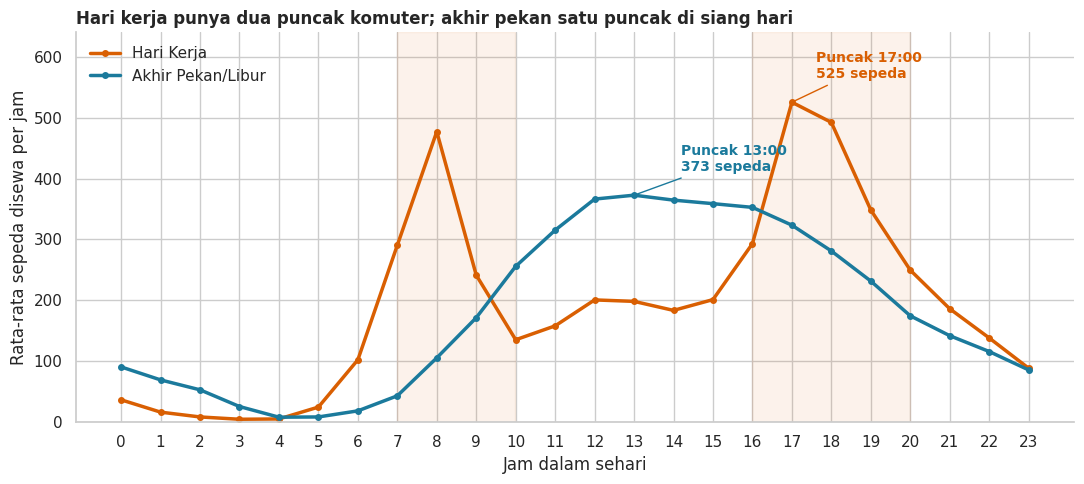

In [22]:
fig, ax = plt.subplots(figsize=(11, 5))
colors = {"Hari Kerja": "#d95f02", "Akhir Pekan/Libur": "#1b7a9c"}
for t, c in colors.items():
    s = hourly_pattern[t]
    ax.plot(s.index, s.values, marker="o", ms=4, lw=2.5, color=c, label=t)
    top = s.idxmax()
    ax.annotate(f"Puncak {top}:00\n{s.max():.0f} sepeda", xy=(top, s.max()),
                xytext=(top + (0.6 if t == "Hari Kerja" else 1.2), s.max() + 40),
                color=c, fontsize=10, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=c))
ax.axvspan(7, 9.99, color="#d95f02", alpha=0.08)
ax.axvspan(16, 19.99, color="#d95f02", alpha=0.08)
ax.set_xticks(range(0, 24))
ax.set_xlabel("Jam dalam sehari"); ax.set_ylabel("Rata-rata sepeda disewa per jam")
ax.set_title("Hari kerja punya dua puncak komuter; akhir pekan satu puncak di siang hari", loc="left", fontweight="bold")
ax.legend(frameon=False); ax.set_ylim(0, 640)
sns.despine(); plt.tight_layout(); plt.show()

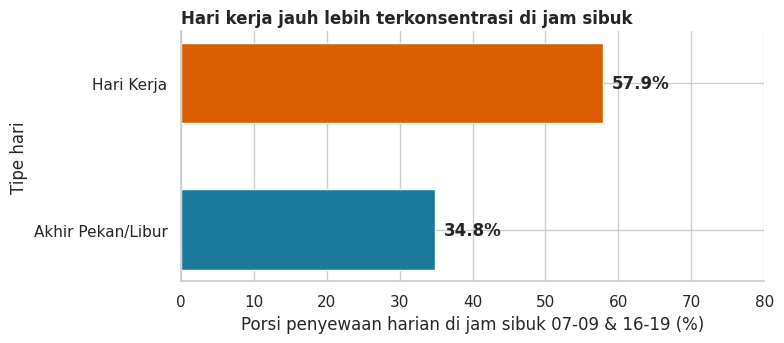

In [23]:
share = pd.Series({t: peak_share(g) for t, g in hour_df.groupby("day_type")}).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(share.index, share.values, color=["#1b7a9c" if i == "Akhir Pekan/Libur" else "#d95f02" for i in share.index], height=0.55)
for b, v in zip(bars, share.values):
    ax.text(v + 1.2, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontweight="bold")
ax.set_xlim(0, 80)
ax.set_xlabel("Porsi penyewaan harian di jam sibuk 07-09 & 16-19 (%)")
ax.set_ylabel("Tipe hari")
ax.set_title("Hari kerja jauh lebih terkonsentrasi di jam sibuk", loc="left", fontweight="bold")
sns.despine(); plt.tight_layout(); plt.show()

**Kesimpulan Pertanyaan 1**
- Pada **hari kerja** permintaan memuncak dua kali: pagi sekitar **08.00 (≈477 sepeda/jam)** dan sore sekitar **17.00 (≈525 sepeda/jam)**, yang merupakan puncak tertinggi sepanjang hari. Tiga jam tertinggi adalah 17.00, 18.00, dan 08.00.
- Pada **akhir pekan/libur** hanya ada satu puncak landai di siang hari, sekitar **13.00 (≈373 sepeda/jam)**, dan tidak ada lonjakan komuter.
- Tujuh jam sibuk (07.00–09.59 dan 16.00–19.59) menyumbang **≈57,9%** dari seluruh penyewaan hari kerja, jauh lebih tinggi daripada akhir pekan/libur (**≈34,8%**).
- Permintaan paling sepi terjadi pukul 02.00–05.00 (hari kerja turun hingga ≈5 sepeda/jam), sehingga jendela ini paling aman untuk redistribusi dan pemeliharaan.

### Pertanyaan 2: Berapa persen penurunan rata-rata penyewaan harian pada cuaca berkabut dan hujan/salju ringan dibandingkan cuaca cerah pada masing-masing musim sepanjang 2011–2012, serta pengguna mana (casual atau registered) yang paling terdampak, sehingga operator dapat menyiapkan strategi armada dan insentif saat cuaca buruk?

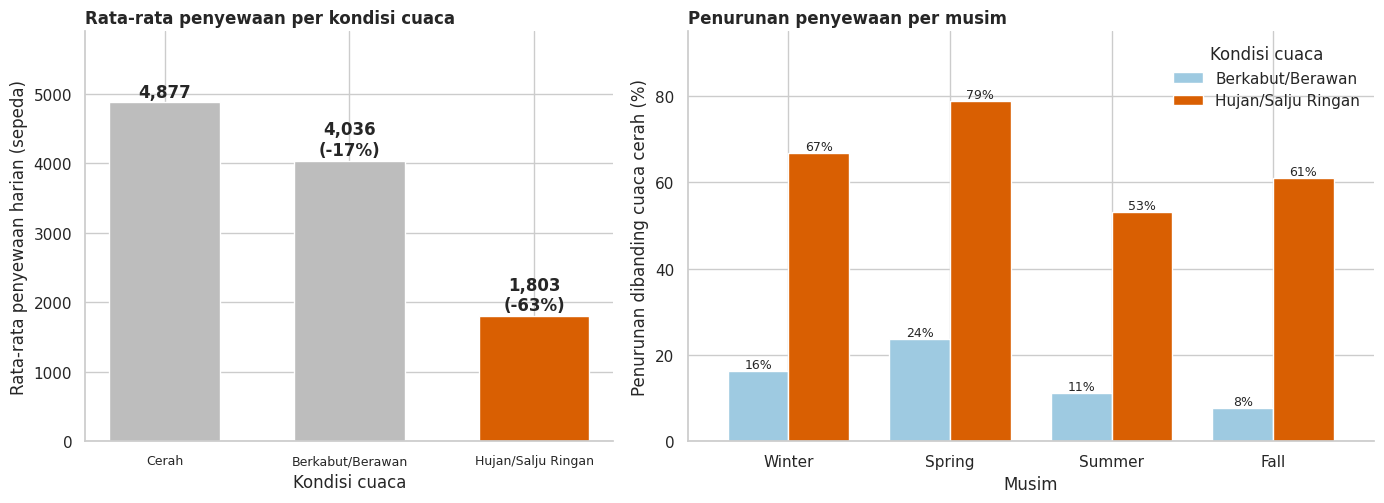

In [24]:
order = ["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.3]})

# (a) rata-rata penyewaan per kondisi cuaca
vals = weather_avg.loc[order, "cnt"]
bars = ax[0].bar(order, vals, color=["#bdbdbd", "#bdbdbd", "#d95f02"], width=0.6)
for b, v, o in zip(bars, vals, order):
    pct = (1 - v / vals["Cerah"]) * 100
    ax[0].text(b.get_x() + b.get_width() / 2, v + 80,
               f"{v:,.0f}" + (f"\n(-{pct:.0f}%)" if o != "Cerah" else ""), ha="center", fontweight="bold")
ax[0].set_xlabel("Kondisi cuaca"); ax[0].set_ylabel("Rata-rata penyewaan harian (sepeda)")
ax[0].set_ylim(0, 5900)
ax[0].set_title("Rata-rata penyewaan per kondisi cuaca", loc="left", fontweight="bold")
ax[0].tick_params(axis="x", labelsize=9)

# (b) persentase penurunan per musim
drop_season = season_weather[["Turun: Berkabut (%)", "Turun: Hujan Ringan (%)"]].copy()
drop_season.columns = ["Berkabut/Berawan", "Hujan/Salju Ringan"]
drop_season.plot(kind="bar", ax=ax[1], color=["#9ecae1", "#d95f02"], width=0.75, rot=0)
for c in ax[1].containers:
    ax[1].bar_label(c, fmt="%.0f%%", fontsize=9)
ax[1].set_xlabel("Musim"); ax[1].set_ylabel("Penurunan dibanding cuaca cerah (%)")
ax[1].set_ylim(0, 95)
ax[1].set_title("Penurunan penyewaan per musim", loc="left", fontweight="bold")
ax[1].legend(title="Kondisi cuaca", frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

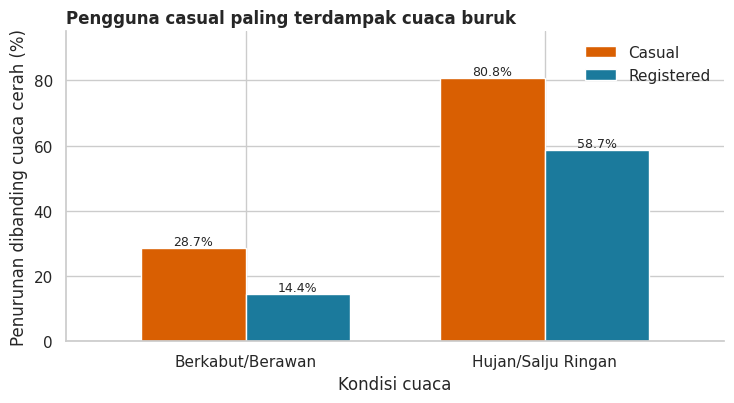

In [25]:
user_drop = drop.loc[["Berkabut/Berawan", "Hujan/Salju Ringan"], ["casual", "registered"]]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
user_drop.plot(kind="bar", ax=ax, color=["#d95f02", "#1b7a9c"], width=0.7, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=9)
ax.set_xlabel("Kondisi cuaca"); ax.set_ylabel("Penurunan dibanding cuaca cerah (%)")
ax.set_ylim(0, 95)
ax.set_title("Pengguna casual paling terdampak cuaca buruk", loc="left", fontweight="bold")
ax.legend(["Casual", "Registered"], frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

**Kesimpulan Pertanyaan 2**
- Dibanding hari cerah (≈**4.877** penyewaan/hari), cuaca **berkabut/berawan turun ≈17,2%** (≈4.036) dan **hujan/salju ringan turun ≈63,0%** (≈1.803).
- Penurunan akibat hujan/salju ringan terjadi di semua musim: ≈**66,7%** (Winter), ≈**78,9%** (Spring), ≈**53,2%** (Summer), dan ≈**61,1%** (Fall). Penurunan terbesar justru di Spring.
- Pengguna **casual turun ≈80,8%** (964 → 185) pada hujan ringan, sedangkan **registered turun ≈58,7%** (3.913 → 1.618). Pengguna casual jauh lebih sensitif terhadap cuaca.
- Suhu berkorelasi positif sedang dengan penyewaan (**r ≈ 0,63**), sedangkan kelembapan (≈ -0,11) dan kecepatan angin (≈ -0,23) berkorelasi lemah.
- Catatan: hanya ada 21 hari bercuaca hujan/salju ringan pada data harian, sehingga angka per musim pada kategori ini perlu dibaca sebagai indikasi, bukan angka pasti.

### Pertanyaan 3: Berapa pertumbuhan total penyewaan bulanan tahun 2012 dibandingkan 2011 (year-over-year), dan pada bulan apa pertumbuhannya paling rendah, sehingga tim marketing dapat memfokuskan promosi pada bulan tersebut?

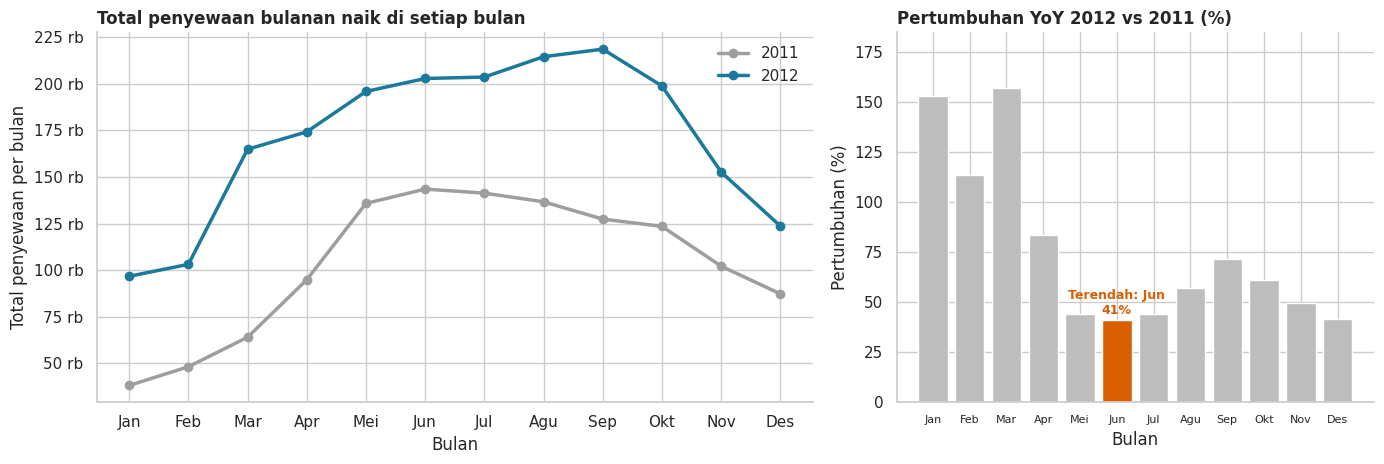

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].plot(month_names, monthly[2011], marker="o", lw=2.5, color="#9e9e9e", label="2011")
ax[0].plot(month_names, monthly[2012], marker="o", lw=2.5, color="#1b7a9c", label="2012")
ax[0].set_ylabel("Total penyewaan per bulan"); ax[0].set_xlabel("Bulan")
ax[0].set_title("Total penyewaan bulanan naik di setiap bulan", loc="left", fontweight="bold")
ax[0].yaxis.set_major_formatter(lambda x, p: f"{x/1000:.0f} rb")
ax[0].legend(frameon=False)

g = monthly["growth_pct"]
low = g.idxmin()
bars = ax[1].bar(month_names, g, color=["#d95f02" if m == low else "#bdbdbd" for m in month_names])
ax[1].set_title("Pertumbuhan YoY 2012 vs 2011 (%)", loc="left", fontweight="bold")
ax[1].text(month_names.index(low), g[low] + 3, f"Terendah: {low}\n{g[low]:.0f}%", ha="center", color="#d95f02", fontweight="bold", fontsize=9)
ax[1].set_ylim(0, 185); ax[1].set_xlabel("Bulan"); ax[1].set_ylabel("Pertumbuhan (%)")
ax[1].tick_params(axis="x", labelsize=8)
sns.despine(); plt.tight_layout(); plt.show()

**Kesimpulan Pertanyaan 3**
- Total penyewaan 2012 (**2.049.576**) tumbuh **≈64,9%** dibandingkan 2011 (**1.243.103**), dan tumbuh di seluruh 12 bulan.
- Pertumbuhan tertinggi terjadi pada **Maret (≈157%)** dan **Januari (≈153%)** yang basis 2011-nya rendah. Pertumbuhan **terendah pada Juni (≈41%)**, disusul Desember (≈42%), Mei dan Juli (≈44%).
- Meski pertumbuhan Juni paling rendah, volume absolutnya tinggi (≈202.830 penyewaan), sehingga bulan-bulan musim panas sudah mendekati kapasitas pasar yang ada. Peluang tambahan lebih besar di bulan dingin dengan volume absolut rendah (Jan–Feb dan Des).

## Analisis Lanjutan (Opsional)

**Teknik: Manual Grouping & Binning**

**Tujuan:** teknik *RFM* dan *geospatial* tidak relevan karena dataset tidak memuat data pelanggan individu maupun lokasi. Oleh karena itu digunakan **Manual Grouping** (aturan bisnis) dan **Binning** untuk mengelompokkan jam, suhu, dan tingkat permintaan harian tanpa algoritma *machine learning*.

1. **Manual grouping jam** menjadi lima segmen waktu operasional (Dini Hari, Jam Sibuk Pagi, Siang, Jam Sibuk Sore, Malam).
2. **Binning suhu** menjadi empat rentang (<10 °C, 10–20 °C, 20–30 °C, >30 °C) untuk melihat sensitivitas terhadap suhu.
3. **Manual grouping tingkat permintaan harian** (Rendah <3.000, Sedang 3.000–5.999, Tinggi ≥6.000 sepeda/hari) untuk melihat sebaran hari berdasarkan musim.

In [27]:
# 1) Segmen waktu (manual grouping)
def time_segment(h):
    if h <= 5:  return "Dini Hari (00-05)"
    if h <= 9:  return "Sibuk Pagi (06-09)"
    if h <= 15: return "Siang (10-15)"
    if h <= 19: return "Sibuk Sore (16-19)"
    return "Malam (20-23)"

hour_df["time_segment"] = hour_df["hr"].apply(time_segment)
seg_order = ["Dini Hari (00-05)", "Sibuk Pagi (06-09)", "Siang (10-15)", "Sibuk Sore (16-19)", "Malam (20-23)"]
seg = hour_df.pivot_table(index="time_segment", columns="day_type", values="cnt", aggfunc="mean").reindex(seg_order).round(0)
seg

day_type,Akhir Pekan/Libur,Hari Kerja
time_segment,,
Dini Hari (00-05),43.0,16.0
Sibuk Pagi (06-09),85.0,278.0
Siang (10-15),339.0,180.0
Sibuk Sore (16-19),297.0,415.0
Malam (20-23),130.0,166.0


In [28]:
# 2) Binning suhu
day_df["temp_bin"] = pd.cut(day_df["temp_c"], bins=[0, 10, 20, 30, 50],
                            labels=["<10 °C", "10-20 °C", "20-30 °C", ">30 °C"])
temp_stat = day_df.groupby("temp_bin", observed=True)["cnt"].agg(["mean", "count"]).round(0)
temp_stat

,mean,count
temp_bin,,
<10 °C,1678.0,60
10-20 °C,3692.0,299
20-30 °C,5662.0,300
>30 °C,5410.0,72


In [29]:
# 3) Tingkat permintaan harian (manual grouping)
day_df["demand_level"] = pd.cut(day_df["cnt"], bins=[0, 2999, 5999, np.inf],
                                labels=["Rendah", "Sedang", "Tinggi"])
demand = pd.crosstab(day_df["season_label"], day_df["demand_level"], normalize="index").reindex(["Winter", "Spring", "Summer", "Fall"]) * 100
demand.round(1)

demand_level,Rendah,Sedang,Tinggi
season_label,,,
Winter,64.6,32.6,2.8
Spring,13.6,52.7,33.7
Summer,2.1,56.4,41.5
Fall,14.6,65.7,19.7


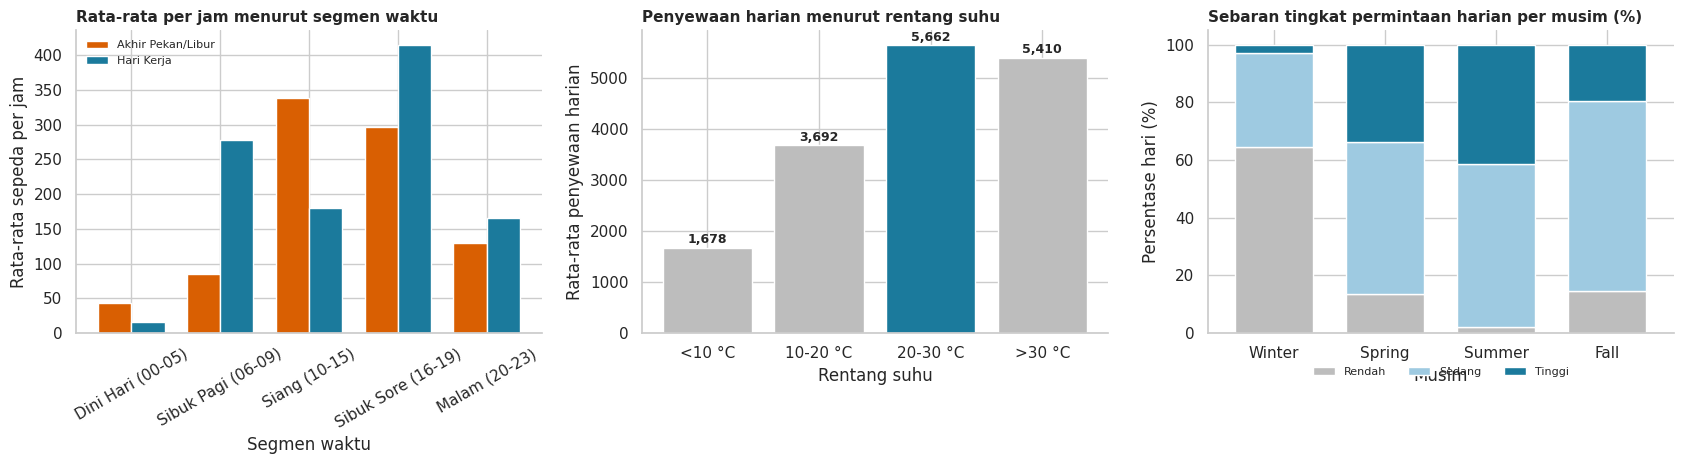

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
seg.plot(kind="bar", ax=ax[0], color=["#d95f02", "#1b7a9c"], rot=30, width=0.75)
ax[0].set_title("Rata-rata per jam menurut segmen waktu", loc="left", fontweight="bold", fontsize=11)
ax[0].set_xlabel("Segmen waktu"); ax[0].set_ylabel("Rata-rata sepeda per jam"); ax[0].legend(frameon=False, fontsize=8)

b = ax[1].bar(temp_stat.index.astype(str), temp_stat["mean"], color=["#bdbdbd", "#bdbdbd", "#1b7a9c", "#bdbdbd"])
for r, v in zip(b, temp_stat["mean"]):
    ax[1].text(r.get_x() + r.get_width() / 2, v + 80, f"{v:,.0f}", ha="center", fontweight="bold", fontsize=9)
ax[1].set_title("Penyewaan harian menurut rentang suhu", loc="left", fontweight="bold", fontsize=11)
ax[1].set_xlabel("Rentang suhu"); ax[1].set_ylabel("Rata-rata penyewaan harian")

demand.plot(kind="bar", stacked=True, ax=ax[2], color=["#bdbdbd", "#9ecae1", "#1b7a9c"], rot=0, width=0.7)
ax[2].set_title("Sebaran tingkat permintaan harian per musim (%)", loc="left", fontweight="bold", fontsize=11)
ax[2].set_xlabel("Musim"); ax[2].set_ylabel("Persentase hari (%)"); ax[2].legend(title="", frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
sns.despine(); plt.tight_layout(); plt.show()

**Insight Analisis Lanjutan**
- Segmen **Sibuk Pagi** (≈278 vs 85 sepeda/jam) dan **Sibuk Sore** (≈415 vs 297) pada hari kerja jauh melampaui akhir pekan, sedangkan akhir pekan lebih unggul pada segmen **Siang** (≈339 vs 180) dan **Dini Hari** (≈43 vs 16).
- Penyewaan harian tertinggi (≈**5.662**) berada pada rentang **20–30 °C**; di atas 30 °C sedikit menurun (≈5.410) dan di bawah 10 °C jatuh drastis (≈1.678). Suhu nyaman, bukan suhu setinggi mungkin, yang mendorong penyewaan.
- Pada **Winter**, ≈64,6% hari berada pada permintaan Rendah dan hanya ≈2,8% hari Tinggi. Sebaliknya **Summer** memiliki ≈41,5% hari Tinggi dan hanya ≈2,1% hari Rendah (Spring ≈33,7% Tinggi). Alokasi armada sebaiknya disesuaikan per musim.

### Simpan Data untuk Dashboard
Data bersih disimpan ke folder `dashboard` dengan hanya kolom yang dibutuhkan dashboard agar ukuran berkas tetap kecil.

In [31]:
hour_cols = ["dteday", "hr", "workingday", "day_type", "season_label", "weather_label", "cnt", "time_segment"]
day_cols = ["dteday", "year", "mnth", "season_label", "weather_label", "cnt", "casual", "registered", "temp_bin", "demand_level"]
hour_df[hour_cols].to_csv("dashboard/main_data.csv", index=False)
day_df[day_cols].to_csv("dashboard/day_data.csv", index=False)
print("main_data.csv:", hour_df[hour_cols].shape, "| day_data.csv:", day_df[day_cols].shape)

main_data.csv: (17379, 8) | day_data.csv: (731, 10)


## Conclusion

### Kesimpulan
1. **Pertanyaan 1:** Hari kerja memiliki dua puncak komuter (≈08.00 dan puncak tertinggi ≈17.00) yang menyumbang ≈57,9% penyewaan harian (akhir pekan ≈34,8%), sedangkan akhir pekan memuncak sekitar 13.00. Jendela paling sepi adalah 02.00–05.00.
2. **Pertanyaan 2:** Dibanding cuaca cerah, cuaca berkabut menurunkan penyewaan ≈17,2% dan hujan/salju ringan ≈63,0%; pengguna *casual* turun ≈80,8% sedangkan *registered* ≈58,7%. Suhu 20–30 °C adalah kondisi dengan penyewaan tertinggi.
3. **Pertanyaan 3:** Total penyewaan tumbuh ≈64,9% pada 2012, positif di semua bulan; pertumbuhan terendah terjadi pada Juni (≈41%) dan Desember (≈42%).

### Rekomendasi (Action Item)
1. **Redistribusi & pemeliharaan armada:** jadwalkan redistribusi sepeda ke stasiun-stasiun komuter **sebelum 07.00 dan sebelum 16.00** pada hari kerja, dan lakukan pemeliharaan/pengecekan di jendela **02.00–05.00**. Saat akhir pekan fokuskan ketersediaan sepeda menjelang siang (10.00–15.00).
2. **Strategi cuaca buruk:** saat prakiraan hujan/salju ringan, kurangi armada yang disebar sekitar 60% dari kondisi normal agar biaya redistribusi lebih efisien. Tawarkan insentif (mis. diskon atau paket langganan hujan) untuk **pengguna casual**, kelompok yang paling terdampak.
3. **Promosi & konversi pengguna:** fokuskan kampanye pada bulan dengan pertumbuhan terendah (**Juni dan Desember**) dan bulan dingin bervolume rendah (Jan–Feb), serta dorong konversi pengguna casual menjadi *registered* karena basis registered lebih stabil terhadap cuaca.
4. **Pengembangan analisis:** lengkapi dengan data lokasi stasiun dan data pengguna individu agar analisis geospasial dan RFM dapat dilakukan pada tahap berikutnya.